In [4]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


PROJECT PANOPTICON
Intelligent Exam Proctoring

Working directory: C:\Users\lenovo\Desktop\santosh lavate

Checking dataset files...
System events file: True
Video telemetry file: True

System events shape: (167, 3)
Video telemetry shape: (10000, 3)

System events columns:
['timestamp', 'tab_switches', 'is_cheating']

Video telemetry columns:
['timestamp', 'eye_gaze_angle', 'audio_db']

First five system events:


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0



First five video telemetry records:


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018



Missing values in system events:


...


Duplicate rows in system events: 0
Duplicate rows in video telemetry: 0

System timestamp column: timestamp
Video timestamp column: timestamp

Temporal merge completed.
Merged dataset shape: (10000, 6)

Numeric feature candidates:
['eye_gaze_angle', 'audio_db', 'tab_switches', 'is_cheating']

Feature engineering completed.
Feature dataset shape: (10000, 14)


,timestamp,eye_gaze_angle,audio_db,system_timestamp,tab_switches,is_cheating,eye_gaze_angle_rolling_mean,eye_gaze_angle_rolling_std,audio_db_rolling_mean,audio_db_rolling_std,tab_switches_rolling_mean,tab_switches_rolling_std,is_cheating_rolling_mean,is_cheating_rolling_std
0,2023-12-01 08:00:00,2.560857,36.553781,2023-12-01 08:00:32.181296,1,0,2.560857,NaN,36.553781,NaN,1.0,NaN,0.0,NaN
1,2023-12-01 08:00:01,10.177137,39.102627,2023-12-01 08:00:32.181296,1,0,6.368997,5.385523,37.828204,1.802307,1.0,0.0,0.0,0.0
2,2023-12-01 08:00:02,5.761714,31.228565,2023-12-01 08:00:32.181296,1,0,6.166569,3.824246,35.628325,4.017781,1.0,0.0,0.0,0.0
3,2023-12-01 08:00:03,9.787105,34.051405,2023-12-01 08:00:32.181296,1,0,7.071703,3.609290,35.234095,3.373926,1.0,0.0,0.0,0.0
4,2023-12-01 08:00:04,4.572665,35.245018,2023-12-01 08:00:32.181296,1,0,6.571896,3.319529,35.236279,2.921910,1.0,0.0,0.0,0.0



Candidate target column: is_cheating

Training data shape: (10000, 11)
Target distribution:


,Count
is_cheating,
0,6688
1,3312



Training samples: 8000
Testing samples: 2000

Model training completed.

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1338
           1       0.99      0.99      0.99       662

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000

Accuracy: 0.9945
Weighted precision: 0.9945026550289869
Weighted recall: 0.9945


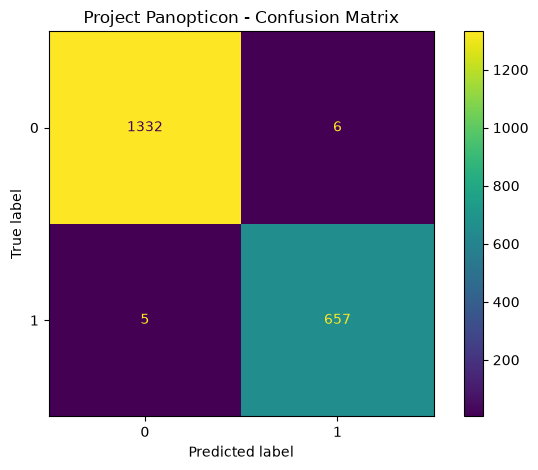


Average Precision: 0.9998158537824473


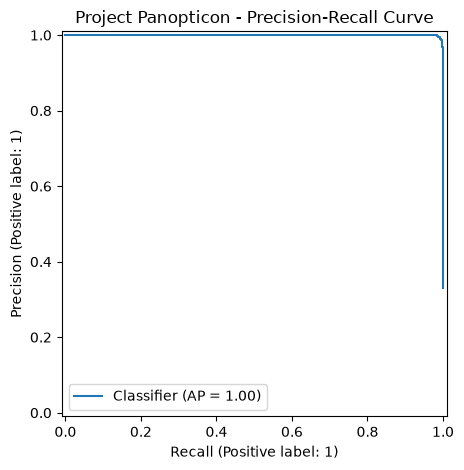


Metrics at threshold 0.90:
Precision: 1.0
Recall: 0.9773413897280967

Top 15 feature importances:


,Importance
is_cheating_rolling_mean,0.659178
tab_switches,0.143850
tab_switches_rolling_mean,0.096173
eye_gaze_angle_rolling_mean,0.027064
audio_db_rolling_mean,0.021306
is_cheating_rolling_std,0.013503
eye_gaze_angle,0.010756
audio_db,0.009359
eye_gaze_angle_rolling_std,0.007435
audio_db_rolling_std,0.006188


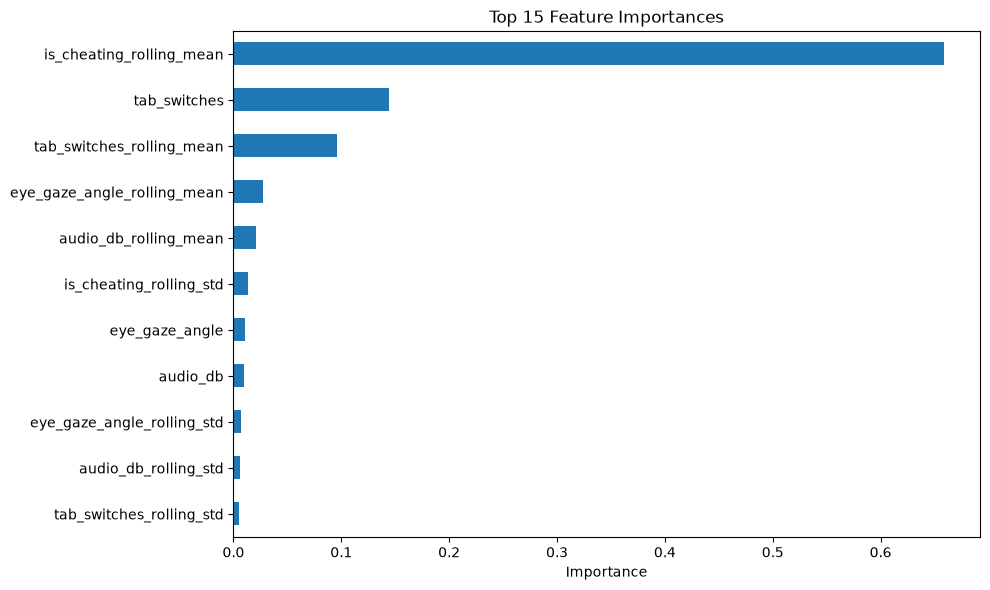


Processed data saved to:
C:\Users\lenovo\Desktop\santosh lavate\panopticon_processed_data.csv

PROJECT EXECUTION FINISHED


In [5]:
# ============================================================
# PROJECT PANOPTICON
# Intelligent Exam Proctoring Using Machine Learning
# Local Windows Jupyter Notebook Version
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    accuracy_score,
    average_precision_score,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RANDOM_STATE = 42
ROLLING_SECONDS = 10
DECISION_THRESHOLD = 0.90

DATA_DIR = Path.cwd()

SYSTEM_FILE = DATA_DIR / "system_events (1) (1).csv"
VIDEO_FILE = DATA_DIR / "video_telemetry (1) (1).csv"

print("=" * 60)
print("PROJECT PANOPTICON")
print("Intelligent Exam Proctoring")
print("=" * 60)

print("\nWorking directory:", DATA_DIR)

# ------------------------------------------------------------
# 2. CHECK DATASET FILES
# ------------------------------------------------------------

print("\nChecking dataset files...")

print("System events file:", SYSTEM_FILE.exists())
print("Video telemetry file:", VIDEO_FILE.exists())

if not SYSTEM_FILE.exists() or not VIDEO_FILE.exists():
    raise FileNotFoundError(
        "\nCSV files nahi mil rahi hain.\n"
        "Dono CSV files ko isi notebook ke folder mein rakho.\n"
        f"Expected system file: {SYSTEM_FILE.name}\n"
        f"Expected video file: {VIDEO_FILE.name}"
    )

# ------------------------------------------------------------
# 3. LOAD DATASETS
# ------------------------------------------------------------

system_df = pd.read_csv(SYSTEM_FILE)
video_df = pd.read_csv(VIDEO_FILE)

print("\nSystem events shape:", system_df.shape)
print("Video telemetry shape:", video_df.shape)

print("\nSystem events columns:")
print(system_df.columns.tolist())

print("\nVideo telemetry columns:")
print(video_df.columns.tolist())

print("\nFirst five system events:")
display(system_df.head())

print("\nFirst five video telemetry records:")
display(video_df.head())

# ------------------------------------------------------------
# 4. DATA QUALITY CHECK
# ------------------------------------------------------------

print("\nMissing values in system events:")
display(system_df.isnull().sum().to_frame("Missing Values"))

print("\nMissing values in video telemetry:")
display(video_df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows in system events:",
      system_df.duplicated().sum())

print("Duplicate rows in video telemetry:",
      video_df.duplicated().sum())

# ------------------------------------------------------------
# 5. IDENTIFY TIMESTAMP COLUMNS
# ------------------------------------------------------------

def find_timestamp_column(df):
    candidates = [
        "timestamp",
        "time",
        "datetime",
        "event_time",
        "recorded_at"
    ]

    lookup = {str(col).lower().strip(): col for col in df.columns}

    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]

    return None


system_time_col = find_timestamp_column(system_df)
video_time_col = find_timestamp_column(video_df)

print("\nSystem timestamp column:", system_time_col)
print("Video timestamp column:", video_time_col)

# ------------------------------------------------------------
# 6. PREPARE DATA FOR TEMPORAL ALIGNMENT
# ------------------------------------------------------------

system_df = system_df.copy()
video_df = video_df.copy()

if system_time_col is not None:
    system_df[system_time_col] = pd.to_datetime(
        system_df[system_time_col],
        errors="coerce"
    )

if video_time_col is not None:
    video_df[video_time_col] = pd.to_datetime(
        video_df[video_time_col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 7. MERGE DATASETS WHEN TIMESTAMPS ARE AVAILABLE
# ------------------------------------------------------------

if system_time_col and video_time_col:

    system_clean = system_df.dropna(
        subset=[system_time_col]
    ).sort_values(system_time_col)

    video_clean = video_df.dropna(
        subset=[video_time_col]
    ).sort_values(video_time_col)

    # Rename duplicate non-time columns to prevent ambiguity.
    rename_map = {
        col: f"system_{col}"
        for col in system_clean.columns
        if col in video_clean.columns
        and col != system_time_col
    }

    system_clean = system_clean.rename(columns=rename_map)

    system_time_name = system_time_col

    if system_time_name in video_clean.columns:
        system_clean = system_clean.rename(
            columns={system_time_name: "system_timestamp"}
        )

    if video_time_col in system_clean.columns:
        video_clean = video_clean.rename(
            columns={video_time_col: "video_timestamp"}
        )

    # Use the video timestamp as the reference timeline.
    merged_df = pd.merge_asof(
        video_clean.sort_values(video_time_col),
        system_clean.sort_values(
            "system_timestamp"
            if "system_timestamp" in system_clean.columns
            else system_time_col
        ),
        left_on=video_time_col,
        right_on=(
            "system_timestamp"
            if "system_timestamp" in system_clean.columns
            else system_time_col
        ),
        direction="nearest"
    )

    print("\nTemporal merge completed.")
    print("Merged dataset shape:", merged_df.shape)

else:
    print(
        "\nTimestamp columns were not identified in both datasets."
    )
    print(
        "Automatic temporal merge skipped to avoid incorrect alignment."
    )

    merged_df = video_df.copy()

# ------------------------------------------------------------
# 8. FEATURE ENGINEERING
# ------------------------------------------------------------

# Convert numeric columns to numeric values where possible.
for col in merged_df.columns:
    if merged_df[col].dtype == "object":
        converted = pd.to_numeric(
            merged_df[col],
            errors="coerce"
        )

        if converted.notna().sum() > 0:
            merged_df[col] = converted

numeric_columns = merged_df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumeric feature candidates:")
print(numeric_columns)

# Generate rolling statistics only for numeric columns.
feature_df = merged_df.copy()

for col in numeric_columns:
    if feature_df[col].notna().sum() > 1:
        feature_df[f"{col}_rolling_mean"] = (
            feature_df[col]
            .rolling(
                window=ROLLING_SECONDS,
                min_periods=1
            )
            .mean()
        )

        feature_df[f"{col}_rolling_std"] = (
            feature_df[col]
            .rolling(
                window=ROLLING_SECONDS,
                min_periods=2
            )
            .std()
        )

print("\nFeature engineering completed.")
print("Feature dataset shape:", feature_df.shape)

display(feature_df.head())

# ------------------------------------------------------------
# 9. IDENTIFY A VALID TARGET LABEL
# ------------------------------------------------------------

possible_target_names = [
    "label",
    "target",
    "cheating",
    "is_cheating",
    "cheating_detected",
    "anomaly",
    "is_anomaly",
    "suspicious",
    "violation",
    "event_label",
    "class"
]

column_lookup = {
    str(col).lower().strip(): col
    for col in feature_df.columns
}

target_col = None

for candidate in possible_target_names:
    if candidate in column_lookup:
        target_col = column_lookup[candidate]
        break

print("\nCandidate target column:", target_col)

if target_col is None:
    print("\nAvailable columns:")
    print(feature_df.columns.tolist())

    raise ValueError(
        "\nNo recognized target label was found.\n"
        "Machine learning classification requires a trustworthy "
        "target label.\n"
        "Check the printed column names and identify the actual "
        "label column before training."
    )

# ------------------------------------------------------------
# 10. PREPARE CLASSIFICATION DATA
# ------------------------------------------------------------

model_df = feature_df.copy()

model_df = model_df.dropna(subset=[target_col])

if model_df[target_col].nunique() < 2:
    raise ValueError(
        "Target label contains fewer than two classes. "
        "A classifier cannot learn a distinction from this data."
    )

# Keep numeric columns for the baseline model.
X = model_df.select_dtypes(
    include=np.number
).drop(
    columns=[target_col],
    errors="ignore"
)

# Exclude numeric identifier-like columns only when appropriate.
# Review the resulting feature list before interpreting the model.
y = model_df[target_col]

# Encode categorical targets if needed.
if y.dtype == "object":
    y = y.astype("category").cat.codes

# Remove columns containing no usable values.
X = X.dropna(axis=1, how="all")

# Remove constant features.
X = X.loc[:, X.nunique(dropna=True) > 1]

if X.shape[1] == 0:
    raise ValueError(
        "No usable numeric features remain after preprocessing."
    )

print("\nTraining data shape:", X.shape)
print("Target distribution:")
display(y.value_counts().to_frame("Count"))

# ------------------------------------------------------------
# 11. TRAIN-TEST SPLIT
# ------------------------------------------------------------

stratify_target = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_target
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ------------------------------------------------------------
# 12. BUILD AND TRAIN RANDOM FOREST
# ------------------------------------------------------------

model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

model.fit(X_train, y_train)

print("\nModel training completed.")

# ------------------------------------------------------------
# 13. PREDICTIONS
# ------------------------------------------------------------

y_pred = model.predict(X_test)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(
    "Weighted precision:",
    precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)
print(
    "Weighted recall:",
    recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

# ------------------------------------------------------------
# 14. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()
plt.title("Project Panopticon - Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 15. PRECISION-RECALL EVALUATION
# ------------------------------------------------------------

classes = np.unique(y_train)

if len(classes) == 2:

    positive_class = classes[-1]

    y_test_binary = (
        np.asarray(y_test) == positive_class
    ).astype(int)

    y_prob = model.predict_proba(X_test)[:, 1]

    ap = average_precision_score(
        y_test_binary,
        y_prob
    )

    print("\nAverage Precision:", ap)

    PrecisionRecallDisplay.from_predictions(
        y_test_binary,
        y_prob
    )

    plt.title("Project Panopticon - Precision-Recall Curve")
    plt.tight_layout()
    plt.show()

    y_threshold_pred = (
        y_prob >= DECISION_THRESHOLD
    ).astype(int)

    print(
        f"\nMetrics at threshold {DECISION_THRESHOLD:.2f}:"
    )

    print(
        "Precision:",
        precision_score(
            y_test_binary,
            y_threshold_pred,
            zero_division=0
        )
    )

    print(
        "Recall:",
        recall_score(
            y_test_binary,
            y_threshold_pred,
            zero_division=0
        )
    )

else:
    print(
        "\nPrecision-Recall threshold analysis skipped: "
        "the target is not binary."
    )

# ------------------------------------------------------------
# 16. FEATURE IMPORTANCE
# ------------------------------------------------------------

rf = model.named_steps["classifier"]

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 15 feature importances:")
display(importance.head(15).to_frame("Importance"))

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 17. SAVE PROCESSED DATA
# ------------------------------------------------------------

output_file = DATA_DIR / "panopticon_processed_data.csv"

feature_df.to_csv(
    output_file,
    index=False
)

print("\nProcessed data saved to:")
print(output_file)

print("\nPROJECT EXECUTION FINISHED")